In [7]:
import pandas as pd

df = pd.read_csv("cs-training.csv", index_col=0)

print(df.shape)                      # berapa baris dan kolom
print(df["SeriousDlqin2yrs"].value_counts(normalize=True) * 100)  # persen macet vs lancar
print(df.isnull().sum())             # kolom mana yang banyak kosong

(150000, 11)
SeriousDlqin2yrs
0    93.316
1     6.684
Name: proportion, dtype: float64
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, recall_score, precision_score

# 1. Pisahkan jawaban (y) dari keterangan (X)
y = df["SeriousDlqin2yrs"]
X = df.drop(columns="SeriousDlqin2yrs")

# 2. Penanda: apakah penghasilan tadinya kosong?
X["IncomeMissing"] = X["MonthlyIncome"].isnull().astype(int)

# 3. Bagi data: 80% untuk belajar, 20% untuk ujian
#    stratify=y menjaga proporsi 6,7% macet tetap sama di kedua bagian
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 4. Model sederhana: isi kosong dengan median, samakan skala, lalu Logistic Regression
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
model.fit(X_train, y_train)

# 5. Nilai di data ujian
proba = model.predict_proba(X_test)[:, 1]
pred = model.predict(X_test)

print("ROC-AUC  :", round(roc_auc_score(y_test, proba), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))

ROC-AUC  : 0.802
Recall   : 0.669
Precision: 0.181


In [9]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd

# Rasio lancar : macet, untuk memberi tahu XGBoost bahwa yang macet lebih penting
rasio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": model,   # sudah dilatih tadi
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                               class_weight="balanced_subsample",
                               n_jobs=-1, random_state=42),
    ),
    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                      scale_pos_weight=rasio, eval_metric="auc",
                      random_state=42),
    ),
}

hasil = []
for nama, m in models.items():
    if nama != "Logistic Regression":
        m.fit(X_train, y_train)
    proba = m.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    hasil.append({
        "Model": nama,
        "ROC-AUC": round(roc_auc_score(y_test, proba), 3),
        "Recall": round(recall_score(y_test, pred), 3),
        "Precision": round(precision_score(y_test, pred), 3),
    })

print(pd.DataFrame(hasil))

                 Model  ROC-AUC  Recall  Precision
0  Logistic Regression    0.802   0.669      0.181
1        Random Forest    0.864   0.664      0.281
2              XGBoost    0.869   0.779      0.220


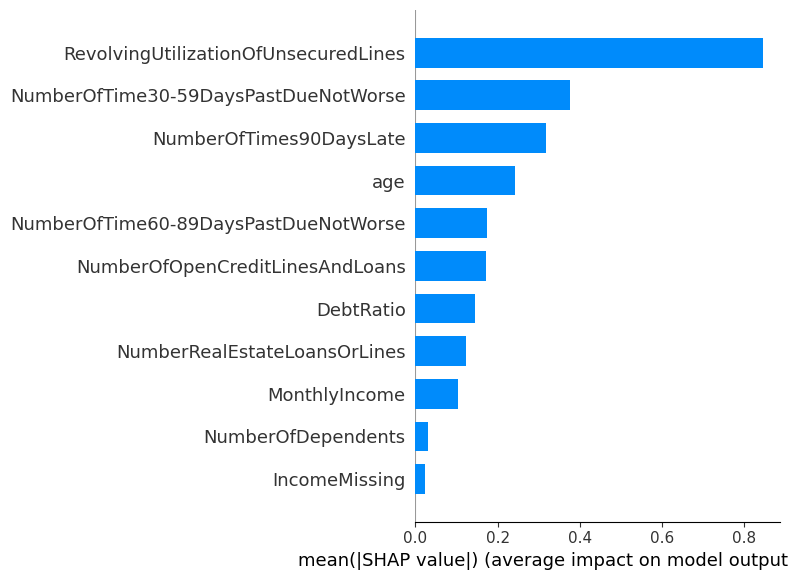

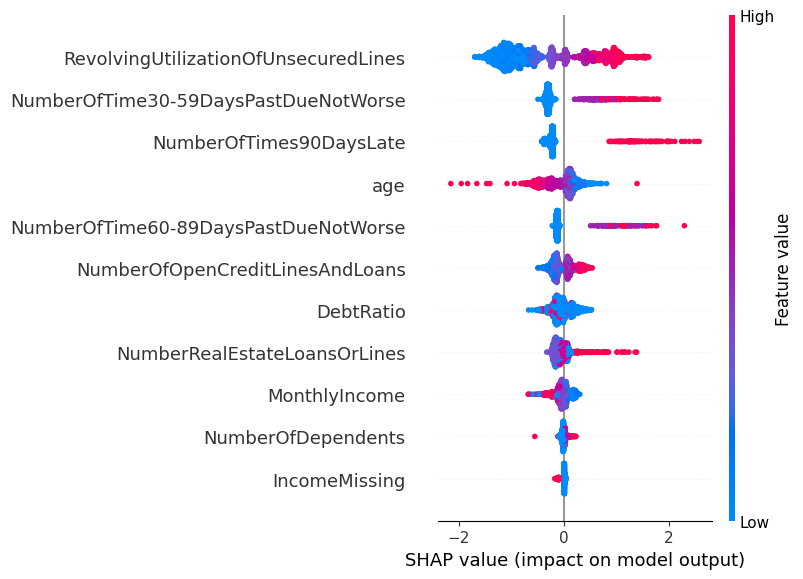

In [10]:
!pip install shap -q

import shap

# Ambil bagian-bagian model XGBoost dari pipeline
imputer = models["XGBoost"].named_steps["simpleimputer"]
xgb = models["XGBoost"].named_steps["xgbclassifier"]

# Data ujian yang sudah diisi (supaya sama dengan yang dilihat model)
X_test_isi = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns)

# Ambil 2.000 peminjam acak saja agar cepat
contoh = X_test_isi.sample(2000, random_state=42)

explainer = shap.TreeExplainer(xgb)
nilai_shap = explainer.shap_values(contoh)

# Gambar 1: kolom mana yang paling berpengaruh
shap.summary_plot(nilai_shap, contoh, plot_type="bar")

# Gambar 2: pengaruhnya ke arah mana
shap.summary_plot(nilai_shap, contoh)

    Batas  Macet lolos  Baik ditolak  Total biaya  Recall  Precision
0    0.05            5         26889        26939   0.998      0.069
1    0.10           27         21808        22078   0.987      0.083
2    0.15           67         17266        17936   0.967      0.101
3    0.20          117         14156        15326   0.942      0.118
4    0.25          163         12010        13640   0.919      0.133
5    0.30          202         10378        12398   0.899      0.148
6    0.35          248          8990        11470   0.876      0.163
7    0.40          305          7797        10847   0.848      0.179
8    0.45          373          6674        10404   0.814      0.196
9    0.50          444          5550         9990   0.779      0.220
10   0.55          530          4526         9826   0.736      0.246
11   0.60          630          3593         9893   0.686      0.277
12   0.65          738          2858        10238   0.632      0.307
13   0.70          829          22

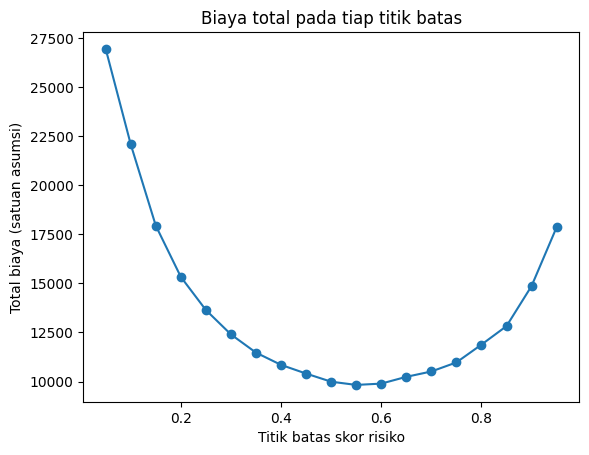

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

proba = models["XGBoost"].predict_proba(X_test)[:, 1]

BIAYA_MACET_LOLOS = 10    # asumsi
BIAYA_BAIK_DITOLAK = 1    # asumsi

hasil = []
for batas in np.arange(0.05, 0.96, 0.05):
    pred = (proba >= batas).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    biaya = fn * BIAYA_MACET_LOLOS + fp * BIAYA_BAIK_DITOLAK
    hasil.append({
        "Batas": round(batas, 2),
        "Macet lolos": fn,
        "Baik ditolak": fp,
        "Total biaya": biaya,
        "Recall": round(tp / (tp + fn), 3),
        "Precision": round(tp / (tp + fp), 3) if (tp + fp) > 0 else 0,
    })

tabel = pd.DataFrame(hasil)
print(tabel)

# Titik batas dengan biaya paling murah
terbaik = tabel.loc[tabel["Total biaya"].idxmin()]
print("\nBatas terbaik:\n", terbaik)

# Pembanding: kalau bank menyetujui semua tanpa model
biaya_tanpa_model = y_test.sum() * BIAYA_MACET_LOLOS
print("\nBiaya tanpa model:", biaya_tanpa_model)

# Grafik
plt.plot(tabel["Batas"], tabel["Total biaya"], marker="o")
plt.xlabel("Titik batas skor risiko")
plt.ylabel("Total biaya (satuan asumsi)")
plt.title("Biaya total pada tiap titik batas")
plt.show()

In [12]:
for rasio in [3, 5, 10, 20]:
    biaya = tabel["Macet lolos"] * rasio + tabel["Baik ditolak"]
    i = biaya.idxmin()
    print(f"Rasio {rasio}:1 -> batas terbaik {tabel.loc[i, 'Batas']}, total biaya {biaya[i]}")

Rasio 3:1 -> batas terbaik 0.85, total biaya 4491
Rasio 5:1 -> batas terbaik 0.75, total biaya 6347
Rasio 10:1 -> batas terbaik 0.55, total biaya 9826
Rasio 20:1 -> batas terbaik 0.4, total biaya 13897
